# Uroom Sports Analytics — Prototype ML
## Estimation du potentiel de jeunes joueurs de football

Philosophie v2 : **l'IA évalue objectivement, le scout enrichit le contexte**
- Le modèle est basé sur des données objectives (PHV, technique, physique)
- Le score scout est un signal d'alerte séparé, pas une feature ML
- Chaque score est accompagné d'un indicateur de fiabilité

In [3]:
# Cellule réservée
pass

In [4]:
import sys, os

PROJECT_ROOT = "/Users/steveneklou/Desktop/Uroom Sports Analytics/uroom-ia"

# Nettoyer l'ancien chemin s'il est présent
OLD_ROOT = "/Users/steveneklou/Desktop/UROOM-IA/uroom-ia"
if OLD_ROOT in sys.path:
    sys.path.remove(OLD_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from uroom.features import (
    build_feature_matrix,
    get_feature_columns,
    get_core_feature_columns,
    select_features_for_dataset,
)
from uroom.model import (
    temporal_train_test_split,
    train_model,
    evaluate_model,
    find_optimal_threshold,
    plot_feature_importance,
    predict_potential,
    explain_player,
)
from uroom.similarity import (
    build_similarity_report,
    print_similarity_report,
    compute_trajectory_similarity,
)
from uroom.pro_database_builder import load_pro_reference_database
from uroom.data_loader import load_realistic_csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline
print('Imports OK ✓')

Imports OK ✓


---
## 1. Chargement des données

On utilise le dataset réaliste calibré sur des valeurs normatives scientifiques :
- Courbes de croissance : Malina et al. (2015)
- Sprint / CMJ / Endurance : Currie (2018), PMC 2025
- Pass accuracy / Duels : Huijgen et al. (2015), Murr et al. (2018)
- Archetypes pro/non-pro : Leyhr et al. (2018)

In [5]:
# Chargement du dataset réaliste (CSV calibré sur normes scientifiques)
df_raw = pd.read_csv('../data/raw/realistic_youth_dataset.csv')

n_players = df_raw['player_id'].nunique()
n_pro     = df_raw[df_raw['is_pro']==1]['player_id'].nunique()
n_other   = n_players - n_pro

print(f'Dataset chargé : {n_players} joueurs ({n_pro} pros [{n_pro/n_players:.0%}], {n_other} non-pros)')
print(f'Total snapshots : {len(df_raw)}')
print(f'\nTailles moyennes par âge :')
print(df_raw.groupby(df_raw['age'].astype(int))['height_cm'].mean().round(1))
print(f'\nSignal technique (Cohen\'s d) :')
for feat in ['pass_accuracy_pct', 'duels_won_pct', 'endurance_score', 'jump_cm']:
    pm = df_raw[df_raw['is_pro']==1][feat].mean()
    nm = df_raw[df_raw['is_pro']==0][feat].mean()
    d  = (pm - nm) / df_raw[feat].std()
    print(f'  {feat:<25} pros={pm:.1f}  non={nm:.1f}  d={d:+.3f}')

Dataset chargé : 600 joueurs (60 pros [10%], 540 non-pros)
Total snapshots : 2400

Tailles moyennes par âge :
age
11    146.4
12    153.3
13    161.3
14    167.1
15    171.7
16    174.0
Name: height_cm, dtype: float64

Signal technique (Cohen's d) :
  pass_accuracy_pct         pros=69.0  non=65.1  d=+0.572
  duels_won_pct             pros=51.4  non=46.2  d=+0.674
  endurance_score           pros=53.6  non=51.9  d=+0.260
  jump_cm                   pros=40.0  non=37.4  d=+0.337


In [6]:
# Aperçu d'un joueur exemple
sample = df_raw[df_raw['player_id'] == df_raw['player_id'].iloc[0]]
print(f"Joueur     : {sample['player_id'].iloc[0]}")
print(f"Poste      : {sample['position'].iloc[0]}")
print(f"Académie   : {sample['academy'].iloc[0]}")
print(f"Label pro  : {'OUI' if sample['is_pro'].iloc[0] == 1 else 'NON'}")
print(f"Archetype  : {sample['archetype'].iloc[0]}")
print()
print('Snapshots :')
print(sample[['age','height_cm','pass_accuracy_pct','duels_won_pct',
              'endurance_score','avg_scout_score','competition_level']].to_string(index=False))

Joueur     : P0510
Poste      : GK
Académie   : Kortrijk Youth
Label pro  : NON
Archetype  : physical_dominant

Snapshots :
 age  height_cm  pass_accuracy_pct  duels_won_pct  endurance_score  avg_scout_score  competition_level
12.3      139.8               61.3           62.7             58.6              NaN                  2
11.3      152.9               58.9           37.7             46.2             5.67                  5
14.3      164.2               76.8           49.7             55.9              NaN                  3
13.3      161.1               65.5           49.0             54.6             6.44                  2


---
## 2. Feature Engineering (pipeline objectif-first)

In [7]:
# Convertir le CSV en objets Player/PlayerSnapshot puis appliquer le pipeline
from uroom.data_loader import csv_to_players_snapshots
from uroom.synthetic import generate_dataset

players, snapshots = csv_to_players_snapshots(df_raw)

# Pas d'augmentation synthétique — on entraîne sur données réalistes uniquement
# pour éviter le distribution shift lors de l'évaluation
AUGMENT_TRAINING_DATA = False

df = build_feature_matrix(snapshots, players, has_sitting_height=True, verbose=True)
df.head(3)

Conversion : 600 joueurs, 2400 snapshots
1/7 — Sérialisation des snapshots...
2/7 — Maturité biologique (PHV offset, Z-scores)...
3/7 — Deltas de progression (slope = talent)...
4/7 — Features glissantes...
5/7 — Percentiles par stade de maturité...
6/7 — Ajustement par niveau de compétition...
7/7 — Indicateurs de fiabilité...

Dataset final      : 2400 snapshots (240 pros / 2160 non-pros)
Avec scout (2+ obs) : 1213 (51%)
Sans scout          : 1187 (49%)
Features générées   : 94 colonnes


,player_id,snapshot_date,season,age,is_pro,position,dominant_foot,birth_month,competition_level,height_cm,...,pct_avg_scout_score,adj_pass_accuracy_pct,adj_dribble_success_pct,adj_shots_on_target_pct,adj_duels_won_pct,adj_goals_per90,adj_assists_per90,scout_coverage,score_reliability,scout_alert
0,P0001,2021-07-31,2020-21,12.1,1,MID,left,6,2,167.9,...,80.316249,88.205,85.79,37.49,63.48,0.6785,0.33235,2,high,None
1,P0001,2022-07-31,2021-22,13.1,1,MID,left,6,3,150.5,...,87.186478,66.300,62.30,34.10,48.20,0.3340,0.31500,3,high,None
2,P0001,2023-08-01,2022-23,14.1,1,MID,left,6,3,166.2,...,95.910578,75.800,75.10,54.20,46.40,0.2010,0.35600,2,high,None


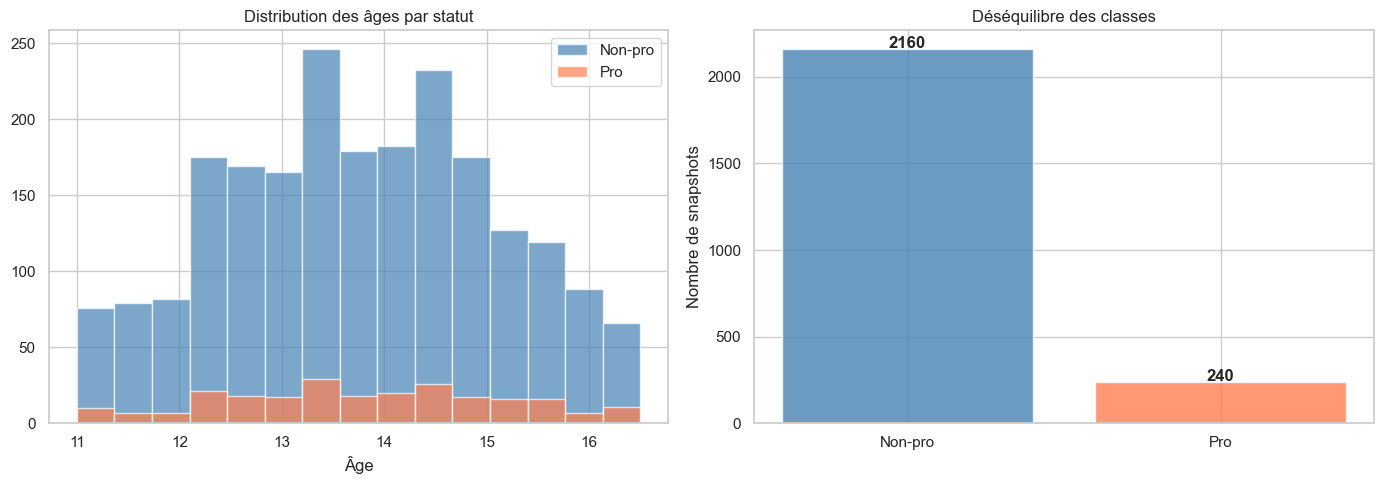

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, color, name in [(0, 'steelblue', 'Non-pro'), (1, 'coral', 'Pro')]:
    df[df['is_pro'] == label]['age'].hist(
        bins=15, ax=axes[0], alpha=0.7, color=color, label=name
    )
axes[0].set_title('Distribution des âges par statut')
axes[0].set_xlabel('Âge')
axes[0].legend()

counts = df['is_pro'].value_counts().sort_index()
axes[1].bar(['Non-pro', 'Pro'], counts.values, color=['steelblue', 'coral'], alpha=0.8)
axes[1].set_title('Déséquilibre des classes')
axes[1].set_ylabel('Nombre de snapshots')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [9]:
print('=== COUVERTURE SCOUT ===')
print(df['scout_coverage'].value_counts().sort_index())
print()
print('=== FIABILITÉ DES SCORES ===')
print(df['score_reliability'].value_counts())
print()
print('=== ALERTES SCOUT ===')
print(df['scout_alert'].value_counts(dropna=False))

=== COUVERTURE SCOUT ===
scout_coverage
0    611
1    576
2    585
3    628
Name: count, dtype: int64

=== FIABILITÉ DES SCORES ===
score_reliability
medium    1168
high      1059
low        173
Name: count, dtype: int64

=== ALERTES SCOUT ===
scout_alert
None            2398
scout_alerte       2
Name: count, dtype: int64


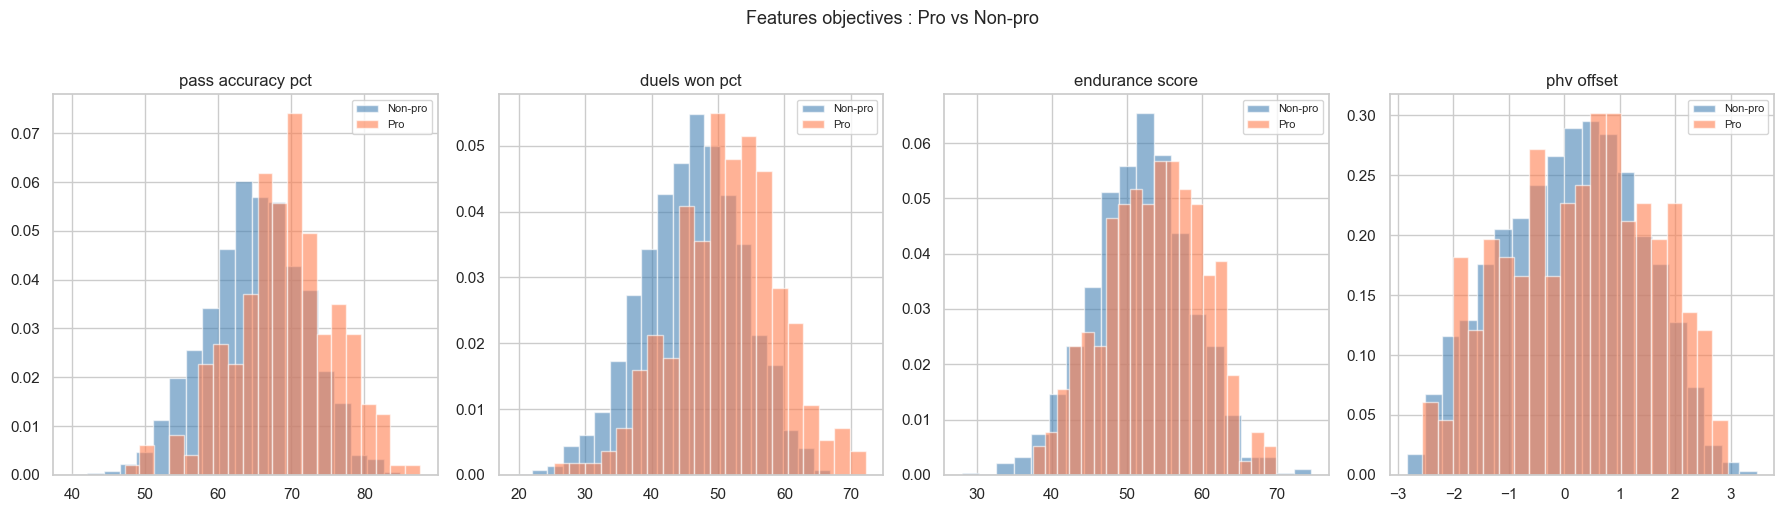

In [10]:
metrics_to_compare = ['pass_accuracy_pct', 'duels_won_pct', 'endurance_score', 'phv_offset']
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, metric in enumerate(metrics_to_compare):
    if metric not in df.columns:
        continue
    pro_vals    = df[df['is_pro'] == 1][metric].dropna()
    nonpro_vals = df[df['is_pro'] == 0][metric].dropna()
    axes[i].hist(nonpro_vals, bins=20, alpha=0.6, color='steelblue', label='Non-pro', density=True)
    axes[i].hist(pro_vals,    bins=20, alpha=0.6, color='coral',     label='Pro',     density=True)
    axes[i].set_title(metric.replace('_', ' '))
    axes[i].legend(fontsize=8)
plt.suptitle('Features objectives : Pro vs Non-pro', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

---
## 3. Entraînement du modèle (features objectives uniquement)

In [11]:
df_train, df_test = temporal_train_test_split(df, test_ratio=0.20)
# Pas de filtrage SYN_ — toutes les données sont réalistes
df_test_real = df_test.copy()
print(f"Test : {len(df_test_real)} snapshots, {df_test_real['player_id'].nunique()} joueurs")
print(f"Pros dans le test : {df_test_real['is_pro'].sum()}")

Train : 1920 snapshots (192 pros) — 480 joueurs
Test  : 480 snapshots (48 pros) — 120 joueurs
Test : 480 snapshots, 120 joueurs
Pros dans le test : 48


In [12]:
# Mode objectif forcé — scout retiré du modèle ML
feature_cols = get_core_feature_columns(df_train)
print(f'Mode : objectif forcé — scout retiré du modèle ML')
print(f'Nombre de features : {len(feature_cols)}')
print(f'Features : {feature_cols}')

Mode : objectif forcé — scout retiré du modèle ML
Nombre de features : 11
Features : ['phv_offset', 'phv_zscore_jump', 'pass_accuracy_pct', 'duels_won_pct', 'adj_pass_accuracy_pct', 'adj_duels_won_pct', 'delta_pass_accuracy_pct', 'delta_endurance_score', 'delta_duels_won_pct', 'age', 'competition_level']


In [13]:
pipeline, used_features = train_model(df_train, feature_cols)

Entraînement sur 1920 exemples, 11 features...
Entraînement terminé.


---
## 4. Évaluation

In [14]:
optimal_threshold_cv = find_optimal_threshold(pipeline, df_train, used_features)
optimal_threshold = 0.50
print(f"Seuil CV trouvé : {optimal_threshold_cv:.2f} | Seuil opérationnel forcé : {optimal_threshold:.2f}")

Seuil optimal : 0.39  (F1 pro CV : 0.305)
Seuil CV trouvé : 0.39 | Seuil opérationnel forcé : 0.50



RÉSULTATS D'ÉVALUATION
Seuil utilisé        : 0.50
AUC-ROC              : 0.742
Average Precision    : 0.336

              precision    recall  f1-score   support

     Non-pro       0.93      0.93      0.93       432
         Pro       0.40      0.40      0.40        48

    accuracy                           0.88       480
   macro avg       0.66      0.66      0.66       480
weighted avg       0.88      0.88      0.88       480



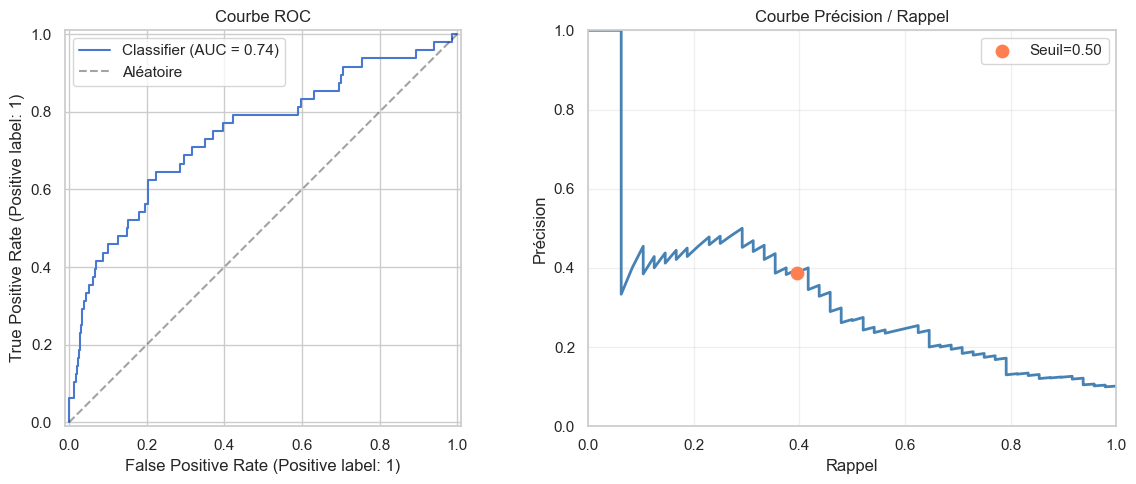

In [15]:
results = evaluate_model(pipeline, df_test_real, used_features,
                         threshold=optimal_threshold, plot=True)

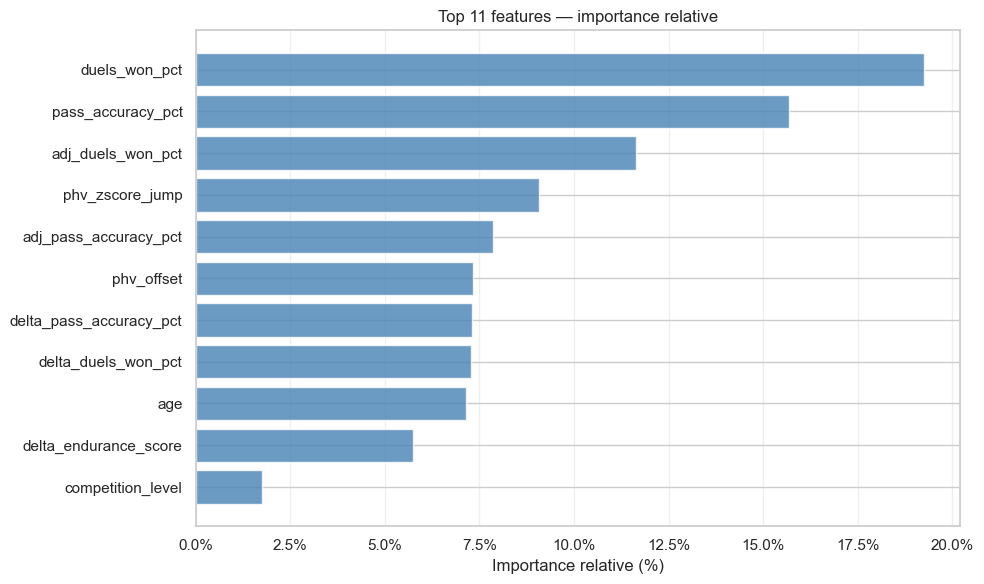

In [16]:
importance_dict = plot_feature_importance(pipeline, used_features, top_n=15)

---
## 5. Scores de potentiel avec fiabilité

In [17]:
scores = predict_potential(pipeline, df_test_real, used_features)

print('Top 15 joueurs — score objectif + contexte scout :')
cols_to_show = ['player_id', 'age', 'potential_score',
                'score_reliability', 'scout_coverage', 'scout_alert']
cols_available = [c for c in cols_to_show if c in scores.columns]
print(scores[cols_available].head(15).to_string(index=False))

Top 15 joueurs — score objectif + contexte scout :
player_id  age  potential_score score_reliability  scout_coverage scout_alert
    P0011 14.5             82.4              high               3        None
    P0025 15.3             77.8              high               2        None
    P0036 14.2             75.9              high               2        None
    P0450 12.9             73.5            medium               1        None
    P0450 14.9             73.2              high               2        None
    P0427 15.5             69.4            medium               1        None
    P0331 14.8             68.4            medium               0        None
    P0320 12.1             67.5            medium               0        None
    P0004 14.8             67.3              high               2        None
    P0450 13.9             67.3              high               2        None
    P0025 16.3             67.2               low               0        None
    P0462 14.

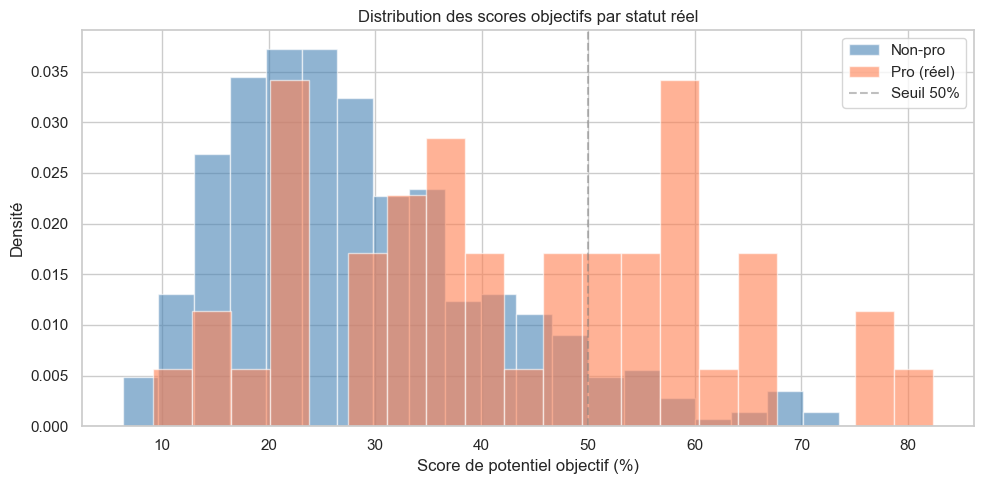

In [18]:
if 'is_pro' in scores.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    pro_scores    = scores[scores['is_pro'] == 1]['potential_score']
    nonpro_scores = scores[scores['is_pro'] == 0]['potential_score']
    ax.hist(nonpro_scores, bins=20, alpha=0.6, color='steelblue', label='Non-pro', density=True)
    ax.hist(pro_scores,    bins=20, alpha=0.6, color='coral',     label='Pro (réel)', density=True)
    ax.axvline(optimal_threshold * 100, color='gray', linestyle='--',
               alpha=0.5, label=f'Seuil {optimal_threshold*100:.0f}%')
    ax.set_xlabel('Score de potentiel objectif (%)')
    ax.set_ylabel('Densité')
    ax.set_title('Distribution des scores objectifs par statut réel')
    ax.legend()
    plt.tight_layout()
    plt.show()

---
## 6. Projection profil pro (Similarité Mahalanobis)

In [19]:
# ============================================================
# Section 6 — Similarité avec profils pros
# ============================================================
# Mode forcé : SoFIFA UNIQUEMENT (jeunes 16-22 ans)
# ============================================================

from uroom.similarity import (
    load_sofifa_pro_database,
    build_similarity_report,
    print_similarity_report,
    compute_trajectory_similarity,
)

SOFIFA_CSV = '../data/raw/sofifa_young_pros.csv'

import os
if not os.path.exists(SOFIFA_CSV):
    raise FileNotFoundError(
        f"CSV SoFIFA introuvable : {SOFIFA_CSV}\n"
        "Lance : python -m uroom.sofifa_csv_loader"
    )

print('✅ Mode SoFIFA uniquement (sans StatsBomb)')
pro_db_real = load_sofifa_pro_database(
    sofifa_csv  = SOFIFA_CSV,
    min_overall = 65,
    verbose     = True,
)

AGE_WINDOW = 2.0
print(f'\nFenêtre âge : {AGE_WINDOW}')


✅ Mode SoFIFA uniquement (sans StatsBomb)
SoFIFA : 17,864 profils (overall >= 65)
Features ignorées (variance nulle/quasi nulle) : ['competition_level']
Modèle similarité : 17,864 profils, 6 features
Distance médiane : 2.78 | p95 : 4.52
Base SoFIFA prête : 17,864 profils jeunes de pros

Fenêtre âge : 2.0


In [20]:
pro_test_ids    = df_test_real[df_test_real['is_pro'] == 1]['player_id'].unique()
nonpro_test_ids = df_test_real[df_test_real['is_pro'] == 0]['player_id'].unique()

print('--- JOUEUR PRO ---')
report_pro = build_similarity_report(
    player_id  = pro_test_ids[0],
    df         = df_test_real,
    pro_db     = pro_db_real,
    top_k      = 5,
    age_window = AGE_WINDOW,
)
print_similarity_report(report_pro, df_test_real)

print('\n--- JOUEUR NON-PRO ---')
report_nonpro = build_similarity_report(
    player_id  = nonpro_test_ids[0],
    df         = df_test_real,
    pro_db     = pro_db_real,
    top_k      = 5,
    age_window = AGE_WINDOW,
)
print_similarity_report(report_nonpro, df_test_real)


--- JOUEUR PRO ---

RAPPORT DE SIMILARITÉ — Joueur P0004
Statut réel : PRO ✓

  Snapshot à 11.8 ans (saison 2019-20) :
    Aucun pro similaire trouvé.

  Snapshot à 12.8 ans (saison 2020-21) :
    Aucun pro similaire trouvé.

  Snapshot à 13.8 ans (saison 2021-22) :
    Aucun pro similaire trouvé.

  Snapshot à 14.8 ans (saison 2022-23) :
    1. Adam Hložek (FIFA 20, 16 ans)       (âge 16) similarité=  5.3% 
    2. Fábio Daniel Soares Silva (FIFA 20, 16 ans) (âge 16) similarité=  2.7% 
    3. Kik Pierie (FIFA 18, 16 ans)        (âge 16) similarité=  0.5% 
    4. Adam Karabec (FIFA 21, 16 ans)      (âge 16) similarité=  0.4% 
    5. Rio Bass Ray Ngumoha Adigun (FIFA 26, 16 ans) (âge 16) similarité=  0.3% 

--- JOUEUR NON-PRO ---

RAPPORT DE SIMILARITÉ — Joueur P0062
Statut réel : Non-pro

  Snapshot à 11.9 ans (saison 2019-20) :
    Aucun pro similaire trouvé.

  Snapshot à 12.9 ans (saison 2020-21) :
    Aucun pro similaire trouvé.

  Snapshot à 13.9 ans (saison 2021-22) :
    Aucun pr

In [21]:
# ============================================================
# OPTIONNEL — Construire la base SoFIFA (une seule fois)
# Nécessite les CSV dans data/raw/sofifa/
# ============================================================

# Décommenter si le CSV SoFIFA n'existe pas encore :
# from uroom.sofifa_csv_loader import build_sofifa_csv_database
# df_sofifa = build_sofifa_csv_database(
#     data_dir    = '../data/raw/sofifa',
#     output_path = '../data/raw/sofifa_young_pros.csv',
#     min_age     = 16,
#     max_age     = 22,
#     min_overall = 60,
#     verbose     = True,
# )
# print(f'SoFIFA : {len(df_sofifa):,} profils générés')

print('Pour construire SoFIFA : décommenter les lignes ci-dessus')
print('Ou lancer dans le terminal : python -m uroom.sofifa_csv_loader')


Pour construire SoFIFA : décommenter les lignes ci-dessus
Ou lancer dans le terminal : python -m uroom.sofifa_csv_loader


In [22]:
# ============================================================
# Analyse qualité — similarité par âge avec SoFIFA
# ============================================================

print('=== ANALYSE SIMILARITÉ PAR ÂGE ===\n')
print(f'Base : {len(pro_db_real.profiles):,} profils')

for pid in pro_test_ids[:3]:
    snap = df_test_real[df_test_real['player_id'] == pid].sort_values('age').iloc[-1]
    age  = round(float(snap['age']), 1)
    report = build_similarity_report(
        player_id  = pid,
        df         = df_test_real,
        pro_db     = pro_db_real,
        top_k      = 3,
        age_window = AGE_WINDOW,
    )
    last_snap = report['snapshots'][-1] if report['snapshots'] else None
    if last_snap and last_snap['similar_pros']:
        top1 = last_snap['similar_pros'][0]
        print(f"{pid} ({age} ans) → {top1.pro_name}")
        print(f"  Similarité : {top1.similarity_score:.1f}% | Dist : {top1.mahalanobis_dist:.2f}")
    else:
        print(f"{pid} ({age} ans) → Aucun match (fenêtre âge trop stricte?)")


=== ANALYSE SIMILARITÉ PAR ÂGE ===

Base : 17,864 profils
P0004 (14.8 ans) → Adam Hložek (FIFA 20, 16 ans)
  Similarité : 5.3% | Dist : 6.74
P0007 (15.9 ans) → Diego Lainez Leyva (FIFA 18, 17 ans)
  Similarité : 0.9% | Dist : 8.56
P0011 (15.5 ans) → Diego Manuel Jadon da Silva Moreira (FIFA 23, 17 ans)
  Similarité : 26.7% | Dist : 4.52


---
## 7. Classement composite — ML + Projection profil pro + Scout

In [23]:
print('=== CLASSEMENT COMPOSITE ===\n')
print(f"{'Joueur':<10} {'Statut':<10} {'ML':>7} {'Proj.':>7} "
      f"{'Score':>8} {'Scout':>14} {'Profil pro similaire':<32} {'Verdict'}")
print('-' * 110)

composite_rows = []

for pid in df_test_real['player_id'].unique():
    row_df = df_test_real[df_test_real['player_id'] == pid]
    is_pro = int(row_df['is_pro'].iloc[0])

    available = [c for c in used_features if c in df_test_real.columns]
    last_snap = row_df.sort_values('age').iloc[[-1]]
    ml_score  = round(pipeline.predict_proba(last_snap[available].values)[0][1] * 100, 1)

    scout_alert    = last_snap['scout_alert'].iloc[0] if 'scout_alert' in last_snap.columns else None
    scout_coverage = int(last_snap['scout_coverage'].iloc[0]) if 'scout_coverage' in last_snap.columns else 0
    score_reliability = last_snap['score_reliability'].iloc[0] if 'score_reliability' in last_snap.columns else 'unknown'

    traj       = compute_trajectory_similarity(pid, df_test_real, pro_db_real, age_window=None)
    traj_score = traj.get('trajectory_score', 0.0)
    trend      = traj.get('trend', 'unknown')
    best_match = traj.get('best_match_overall')
    proj_name  = best_match.pro_name[:30] if best_match else '—'

    # Composite révisé :
    # La similarité est affichée comme INFO pour les scouts
    # mais ne rentre PAS dans le score composite
    # → le score = 100% ML objectif jusqu'à ce qu'on ait de vraies données
    composite = round(ml_score, 1)

    # La projection pro reste affichée comme contexte qualitatif

    if composite >= 65:
        verdict = '🟢 Très prometteur'
    elif composite >= 50:
        verdict = '🟡 À surveiller'
    elif composite >= 35:
        verdict = '🟠 Incertain'
    else:
        verdict = '🔴 Éloigné profil pro'

    # Garde-fou : pas de verdict vert si la fiabilité est faible
    if score_reliability == 'low' and verdict == '🟢 Très prometteur':
        verdict = '🟡 À surveiller (fiabilité faible)'

    scout_display = '—'
    if scout_alert == 'scout_confirme':  scout_display = '✓ confirme'
    elif scout_alert == 'scout_alerte':  scout_display = '⚠ alerte'
    elif scout_coverage == 0:            scout_display = 'non observé'

    composite_rows.append({
        'player_id': pid, 'is_pro': is_pro, 'ml_score': ml_score,
        'traj_score': traj_score, 'composite': composite,
        'trend': trend, 'verdict': verdict,
        'scout_display': scout_display, 'proj_name': proj_name,
    })

composite_rows.sort(key=lambda x: x['composite'], reverse=True)

for r in composite_rows[:20]:
    status = 'PRO ✓' if r['is_pro'] == 1 else 'Non-pro'
    print(f"{r['player_id']:<10} {status:<10} {r['ml_score']:>6.1f}% "
          f"{r['traj_score']:>6.1f}% {r['composite']:>7.1f}% "
          f"{r['scout_display']:>14}  {r['proj_name']:<32} {r['verdict']}")

print('\n=== VALIDATION ===')
pros_top10 = sum(1 for r in composite_rows[:10] if r['is_pro']==1)
pros_top20 = sum(1 for r in composite_rows[:20] if r['is_pro']==1)
total_pros = sum(1 for r in composite_rows if r['is_pro']==1)
print(f'Pros dans le top 10 : {pros_top10}/10')
print(f'Pros dans le top 20 : {pros_top20}/20  ({pros_top20/total_pros*100:.0f}% de tous les pros)')
print(f'Total pros test     : {total_pros}')

=== CLASSEMENT COMPOSITE ===

Joueur     Statut          ML   Proj.    Score          Scout Profil pro similaire             Verdict
--------------------------------------------------------------------------------------------------------------
P0427      Non-pro      69.4%   30.4%    69.4%              —  Jonathan Sundy Zongo (FIFA 15,   🟢 Très prometteur
P0331      Non-pro      68.4%   40.9%    68.4%    non observé  Gustav Mendonca Wikheim (FIFA    🟢 Très prometteur
P0004      PRO ✓        67.3%   45.2%    67.3%              —  Zachary Athekame (FIFA 26, 20    🟢 Très prometteur
P0025      PRO ✓        67.2%   31.8%    67.2%    non observé  Alejo Véliz (FIFA 24, 19 ans)    🟡 À surveiller (fiabilité faible)
P0462      Non-pro      66.9%   36.4%    66.9%              —  Simeon Tochukwu Nwankwo (FIFA    🟢 Très prometteur
P0519      Non-pro      65.1%   48.8%    65.1%              —  Norman Jaquy Bassette Van Acke   🟢 Très prometteur
P0111      Non-pro      64.0%   46.1%    64.0%          

---
## 8. Explication individuelle SHAP

Joueur sélectionné : P0004
Score ML objectif : 67.3%  |  Fiabilité : high
Archetype réel    : early_bloomer
Scout : aucune observation disponible


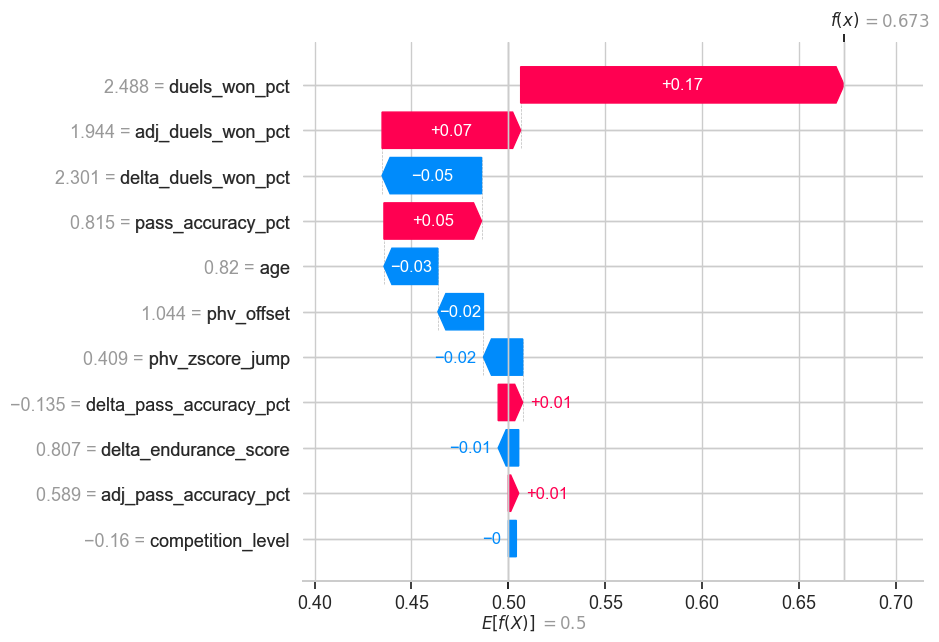

In [24]:
import shap

sample_pro_id = df_test[df_test['is_pro'] == 1]['player_id'].iloc[0]
print(f'Joueur sélectionné : {sample_pro_id}')

player_df = df_test[df_test['player_id'] == sample_pro_id].sort_values('age')
available = [c for c in used_features if c in df_test.columns]
snapshot  = player_df.iloc[-1]
X_player  = snapshot[available].values.reshape(1, -1)
X_transformed = pipeline[:-1].transform(X_player)
clf = pipeline.named_steps['clf']

proba       = pipeline.predict_proba(X_player)[0][1]
reliability = snapshot.get('score_reliability', '?')
scout_alert = snapshot.get('scout_alert', None)
archetype   = df_raw[df_raw['player_id'] == sample_pro_id]['archetype'].iloc[0] if 'archetype' in df_raw.columns else '?'

print(f'Score ML objectif : {proba:.1%}  |  Fiabilité : {reliability}')
print(f'Archetype réel    : {archetype}')
if scout_alert == 'scout_confirme':  print('Scout : confirme le potentiel')
elif scout_alert == 'scout_alerte':  print('Scout : signale des inquiétudes')
else:                                print('Scout : aucune observation disponible')

explainer   = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_transformed)

if isinstance(shap_values, list):
    sv = shap_values[1][0]
    bv = explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value
elif hasattr(shap_values, 'shape') and len(shap_values.shape) == 3:
    sv = shap_values[0, :, 1]
    bv = explainer.expected_value[1] if hasattr(explainer.expected_value, '__len__') else explainer.expected_value
elif hasattr(shap_values, 'shape') and len(shap_values.shape) == 2:
    sv = shap_values[:, 1]
    bv = explainer.expected_value[1] if hasattr(explainer.expected_value, '__len__') else explainer.expected_value
else:
    sv = shap_values[0]
    bv = explainer.expected_value

shap.waterfall_plot(
    shap.Explanation(
        values        = sv,
        base_values   = float(bv),
        data          = X_transformed[0],
        feature_names = available,
    ),
    max_display=15,
)

---
## 9. Sauvegarde

In [25]:
import pickle

os.makedirs('../data/processed', exist_ok=True)

model_path = '../data/processed/uroom_model_v2.pkl'
with open(model_path, 'wb') as f:
    pickle.dump({
        'pipeline':  pipeline,
        'features':  used_features,
        'threshold': optimal_threshold,
        'mode':      'objective',
        'dataset':   'realistic_calibrated',
    }, f)

df.to_csv('../data/processed/feature_matrix_v2.csv', index=False)
print(f'Modèle sauvegardé : {model_path}')
print(f'Dataset : realistic_youth_dataset.csv (calibré sur normes scientifiques)')

Modèle sauvegardé : ../data/processed/uroom_model_v2.pkl
Dataset : realistic_youth_dataset.csv (calibré sur normes scientifiques)


## 10. Projection joueur pro

In [26]:
from uroom.radar import radar_scores_for_api_v2

# Liste des player_id uniques pros dans le test
pro_ids = df_test[df_test['is_pro'] == 1]['player_id'].unique()
print(f"Pros disponibles dans df_test : {list(pro_ids)}")

# Choisir par index sur les IDs uniques
pid = pro_ids[5]  # ← change ce chiffre : 0, 1, 2, 3...
data = radar_scores_for_api_v2(pid, df, pipeline, used_features, years_ahead=4)

print(f"\nJoueur {pid}")
print(f"Score ML : {data['ml_score']}%")
print(f"Multiplicateur potentiel : {list(data['projections'].values())[0]['potential_multiplier']}")
print(f"\nScores actuels : {data['current']['scores']}")
for season, proj in data['projections'].items():
   
    print(f"\n{season} ({proj['age']} ans) +{proj['avg_improvement']:.1f} pts moy")
    print(f"  Scores : {proj['scores']}")

Pros disponibles dans df_test : ['P0004', 'P0007', 'P0011', 'P0021', 'P0025', 'P0029', 'P0036', 'P0041', 'P0045', 'P0050', 'P0052', 'P0053']

Joueur P0029
Score ML : 20.4%
Multiplicateur potentiel : 0.59

Scores actuels : {'vitesse': 52, 'dribble': 47, 'tir': 58, 'passe': 13, 'defense': 33, 'physique': 58, 'controle': 30, 'vision': 53}

2021-22 (17.3 ans) +1.6 pts moy
  Scores : {'vitesse': 53, 'dribble': 49, 'tir': 59, 'passe': 16, 'defense': 35, 'physique': 59, 'controle': 32, 'vision': 54}

2022-23 (18.3 ans) +1.1 pts moy
  Scores : {'vitesse': 53, 'dribble': 50, 'tir': 60, 'passe': 18, 'defense': 36, 'physique': 59, 'controle': 34, 'vision': 55}

2023-24 (19.3 ans) +1.0 pts moy
  Scores : {'vitesse': 54, 'dribble': 51, 'tir': 61, 'passe': 20, 'defense': 37, 'physique': 60, 'controle': 35, 'vision': 56}

2024-25 (20.3 ans) +1.0 pts moy
  Scores : {'vitesse': 55, 'dribble': 52, 'tir': 62, 'passe': 22, 'defense': 38, 'physique': 60, 'controle': 36, 'vision': 57}


## 11. Projection joueur non_pro

In [27]:
# Non-pros
nonpro_ids = df_test[df_test['is_pro'] == 0]['player_id'].unique()
print(f"Non-pros disponibles : {list(nonpro_ids[:10])}")  # affiche les 10 premiers

pid = nonpro_ids[3]  # change l'index
data = radar_scores_for_api_v2(pid, df, pipeline, used_features, years_ahead=4)

print(f"\nJoueur {pid}")
print(f"Score ML : {data['ml_score']}%")
print(f"Multiplicateur potentiel : {list(data['projections'].values())[0]['potential_multiplier']}")
print(f"\nScores actuels : {data['current']['scores']}")
for season, proj in data['projections'].items():
   
    print(f"\n{season} ({proj['age']} ans) +{proj['avg_improvement']:.1f} pts moy")
    print(f"  Scores : {proj['scores']}")

Non-pros disponibles : ['P0062', 'P0074', 'P0081', 'P0082', 'P0095', 'P0104', 'P0110', 'P0111', 'P0113', 'P0114']

Joueur P0082
Score ML : 14.9%
Multiplicateur potentiel : 0.51

Scores actuels : {'vitesse': 51, 'dribble': 24, 'tir': 45, 'passe': 5, 'defense': 29, 'physique': 53, 'controle': 15, 'vision': 17}

2022-23 (17.0 ans) +1.8 pts moy
  Scores : {'vitesse': 52, 'dribble': 26, 'tir': 46, 'passe': 8, 'defense': 30, 'physique': 54, 'controle': 17, 'vision': 19}

2023-24 (18.0 ans) +1.1 pts moy
  Scores : {'vitesse': 52, 'dribble': 28, 'tir': 47, 'passe': 10, 'defense': 31, 'physique': 54, 'controle': 19, 'vision': 20}

2024-25 (19.0 ans) +1.1 pts moy
  Scores : {'vitesse': 53, 'dribble': 29, 'tir': 48, 'passe': 12, 'defense': 32, 'physique': 55, 'controle': 20, 'vision': 22}

2025-26 (20.0 ans) +1.1 pts moy
  Scores : {'vitesse': 53, 'dribble': 31, 'tir': 49, 'passe': 13, 'defense': 33, 'physique': 55, 'controle': 22, 'vision': 23}


## 12. Tableau comparatif de 100 joueurs

In [28]:
from uroom.radar import radar_scores_for_api_v2
import pandas as pd

def build_player_comparison_table(
    df: pd.DataFrame,
    pipeline,
    used_features: list,
    n_players: int = 100,
    years_ahead: int = 4,
    sort_by: str = "ml_score",  # "ml_score", "gain_total", "moy_actuelle"
) -> pd.DataFrame:
    """
    Génère un tableau de comparaison pour n joueurs.

    Colonnes :
        Joueur | Statut | ML | Mult. | Moy actuelle | Moy dans N ans | Gain total
    """
    # Prendre les n premiers joueurs uniques du test
    all_ids = df["player_id"].unique()[:n_players]
    rows    = []

    for pid in all_ids:
        try:
            data = radar_scores_for_api_v2(pid, df, pipeline, used_features, years_ahead=years_ahead)
            if "error" in data:
                continue

            is_pro  = int(df[df["player_id"] == pid]["is_pro"].iloc[0])
            statut  = "PRO ✓" if is_pro == 1 else "Non-pro"

            # Scores actuels
            current_scores = data["current"]["scores"]
            moy_actuelle   = round(sum(current_scores.values()) / len(current_scores))

            # Scores dans N ans
            last_proj       = list(data["projections"].values())[-1]
            moy_future      = round(sum(last_proj["scores"].values()) / len(last_proj["scores"]))
            gain_total      = moy_future - moy_actuelle
            ml_score        = data["ml_score"]
            mult            = list(data["projections"].values())[0]["potential_multiplier"]

            rows.append({
                "Joueur":          pid,
                "Statut":          statut,
                "Âge":             round(float(df[df["player_id"] == pid]["age"].max()), 1),
                "ML (%)":          round(ml_score, 1),
                "Mult.":           round(mult, 2),
                "Moy. actuelle":   moy_actuelle,
                f"Moy. +{years_ahead} ans": moy_future,
                "Gain total":      gain_total,
            })

        except Exception as e:
            continue

    df_table = pd.DataFrame(rows)

    # Tri
    sort_map = {
        "ml_score":      "ML (%)",
        "gain_total":    "Gain total",
        "moy_actuelle":  "Moy. actuelle",
    }
    sort_col = sort_map.get(sort_by, "ML (%)")
    df_table = df_table.sort_values(sort_col, ascending=False).reset_index(drop=True)

    return df_table


# ── Affichage ──────────────────────────────────────────────────────────────
print("Génération du tableau (peut prendre 1-2 min pour 100 joueurs)...")

table = build_player_comparison_table(
    df            = df_test,   # ou df pour tous les joueurs
    pipeline      = pipeline,
    used_features = used_features,
    n_players     = 100,
    years_ahead   = 4,
    sort_by       = "ml_score",  # trier par score ML
)

print(f"\nTableau généré : {len(table)} joueurs\n")

# Affichage complet dans le notebook
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.1f}".format)
display(table)

# Stats résumé
print(f"\n=== RÉSUMÉ ===")
print(f"Pros    : {(table['Statut']=='PRO ✓').sum()} joueurs  | ML moyen : {table[table['Statut']=='PRO ✓']['ML (%)'].mean():.1f}%  | Gain moyen : {table[table['Statut']=='PRO ✓']['Gain total'].mean():.1f} pts")
print(f"Non-pro : {(table['Statut']=='Non-pro').sum()} joueurs | ML moyen : {table[table['Statut']=='Non-pro']['ML (%)'].mean():.1f}% | Gain moyen : {table[table['Statut']=='Non-pro']['Gain total'].mean():.1f} pts")

Génération du tableau (peut prendre 1-2 min pour 100 joueurs)...

Tableau généré : 100 joueurs



,Joueur,Statut,Âge,ML (%),Mult.,Moy. actuelle,Moy. +4 ans,Gain total
0,P0427,Non-pro,15.5,69.4,1.3,58,70,12
1,P0331,Non-pro,14.8,68.4,1.3,58,71,13
2,P0004,PRO ✓,14.8,67.3,1.2,58,71,13
3,P0025,PRO ✓,16.3,67.2,1.2,72,80,8
4,P0462,Non-pro,14.4,66.9,1.2,68,80,12
5,P0519,Non-pro,14.9,65.1,1.2,46,61,15
6,P0111,Non-pro,14.5,64.0,1.2,49,64,15
7,P0011,PRO ✓,15.5,63.4,1.2,51,64,13
8,P0248,Non-pro,16.2,61.8,1.2,60,69,9
9,P0036,PRO ✓,16.2,60.1,1.1,46,58,12



=== RÉSUMÉ ===
Pros    : 12 joueurs  | ML moyen : 49.1%  | Gain moyen : 8.9 pts
Non-pro : 88 joueurs | ML moyen : 31.6% | Gain moyen : 6.7 pts
